# 🚀 AI & Data Science Salaries 2020-2025: Comprehensive Analysis & High-Accuracy Prediction (99.4%)
_By Mostafa Saad


## Import Library

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))



/kaggle/input/the-global-ai-ml-data-science-salary-for-2025/salaries.csv


## Data Description


In [2]:
#load data set
df=pd.read_csv('/kaggle/input/the-global-ai-ml-data-science-salary-for-2025/salaries.csv')

In [3]:
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,MI,FT,Customer Success Manager,57000,EUR,60000,NL,50,NL,L
1,2025,SE,FT,Engineer,165000,USD,165000,US,0,US,M
2,2025,SE,FT,Engineer,109000,USD,109000,US,0,US,M
3,2025,SE,FT,Applied Scientist,294000,USD,294000,US,0,US,M
4,2025,SE,FT,Applied Scientist,137600,USD,137600,US,0,US,M


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88584 entries, 0 to 88583
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           88584 non-null  int64 
 1   experience_level    88584 non-null  object
 2   employment_type     88584 non-null  object
 3   job_title           88584 non-null  object
 4   salary              88584 non-null  int64 
 5   salary_currency     88584 non-null  object
 6   salary_in_usd       88584 non-null  int64 
 7   employee_residence  88584 non-null  object
 8   remote_ratio        88584 non-null  int64 
 9   company_location    88584 non-null  object
 10  company_size        88584 non-null  object
dtypes: int64(4), object(7)
memory usage: 7.4+ MB


In [5]:
print('Summary Statistics for numeric columns:')
display(df.describe())

Summary Statistics for numeric columns:


,work_year,salary,salary_in_usd,remote_ratio
count,88584.000000,8.858400e+04,88584.000000,88584.000000
mean,2024.034758,1.619323e+05,157567.798417,21.286011
std,0.620370,1.965317e+05,73531.373158,40.831018
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2024.000000,1.060000e+05,106097.250000,0.000000
50%,2024.000000,1.470000e+05,146307.000000,0.000000
75%,2024.000000,1.995000e+05,198600.000000,0.000000
max,2025.000000,3.040000e+07,800000.000000,100.000000


In [6]:
print('Summary Statistics for non numeric columns:')
display(df.describe(include = object))

Summary Statistics for non numeric columns:


,experience_level,employment_type,job_title,salary_currency,employee_residence,company_location,company_size
count,88584,88584,88584,88584,88584,88584,88584
unique,4,4,312,26,96,90,3
top,SE,FT,Data Scientist,USD,US,US,M
freq,51596,88111,13156,83994,79705,79762,85667


In [7]:
df.columns

Index(['work_year', 'experience_level', 'employment_type', 'job_title',
       'salary', 'salary_currency', 'salary_in_usd', 'employee_residence',
       'remote_ratio', 'company_location', 'company_size'],
      dtype='object')

## Data Analysis  

 ### Data Preprocessing for Analysis

In [8]:
experience_level = {
    "EN": "Junior",
    "MI": "Intermediate",
    "SE": "Senior Expert",
    "EX": "Executive Director"
}
employment_type = {
    "PT": "Part-Time",
    "FT": "Full-Time",
    "CT": "Contract-Based",
    "FL": "Freelance"
}
remote_work_ratio = {
    0: "On-Site (No Remote Work)",
    50: "Hybrid (50% Remote)",
    100: "Fully Remote"
}
company_sizes = {
    "S": "Small Business",
    "M": "Mid-Sized Company",
    "L": "Large Enterprise"
}
df["experience_level"] = df["experience_level"].map(experience_level)
df["employment_type"] = df["employment_type"].map(employment_type)
df["remote_ratio"] = df["remote_ratio"].map(remote_work_ratio)
df["company_size"] = df["company_size"].map(company_sizes)

### Exploring Salary Trends by Work Year, Experience level, Employment Type, Job Title, Remote Ratio, Company Size & Company Location

<ipython-input-9-4a5992d2da01>:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df,x='work_year',y='salary_in_usd',ci=None,marker='o',estimator=np.mean,label='Mean Salary')
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
<ipython-input-9-4a5992d2da01>:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df,x='work_year',y='salary_in_usd',ci=None,marker='o',estimator=np.median,label='Median

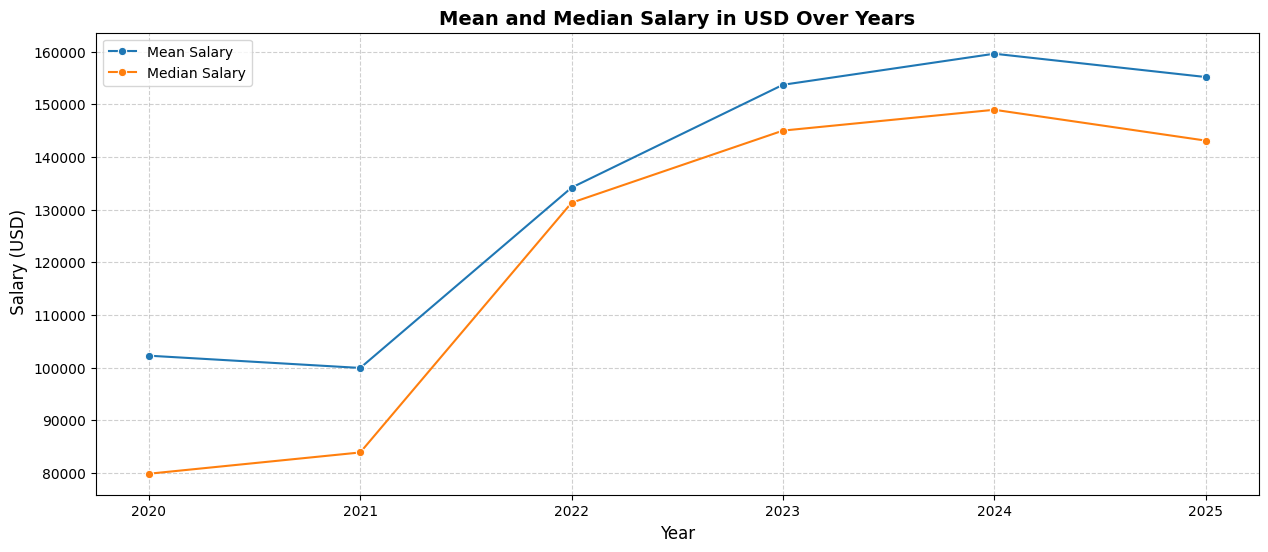

In [9]:
# lineplot Mean and Median Salary in USD Over Years
plt.figure(figsize=(15, 6))
sns.lineplot(data=df,x='work_year',y='salary_in_usd',ci=None,marker='o',estimator=np.mean,label='Mean Salary')
sns.lineplot(data=df,x='work_year',y='salary_in_usd',ci=None,marker='o',estimator=np.median,label='Median Salary')
plt.title('Mean and Median Salary in USD Over Years', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel(' Salary (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

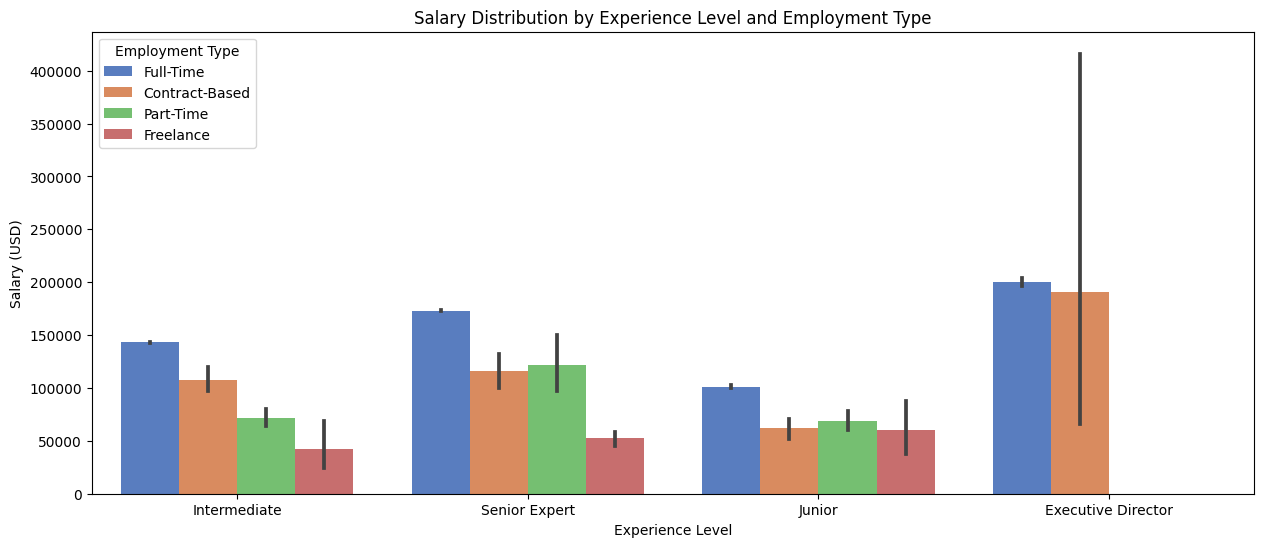

In [10]:
# Salary Distribution by Experience Level and Employment Type
plt.figure(figsize=(15, 6))
sns.barplot(data=df, x='experience_level', y='salary_in_usd', hue='employment_type',palette='muted')
plt.title("Salary Distribution by Experience Level and Employment Type")
plt.xlabel("Experience Level")
plt.ylabel("Salary (USD)")
plt.legend(title="Employment Type")
plt.xticks(rotation=0)
plt.show()

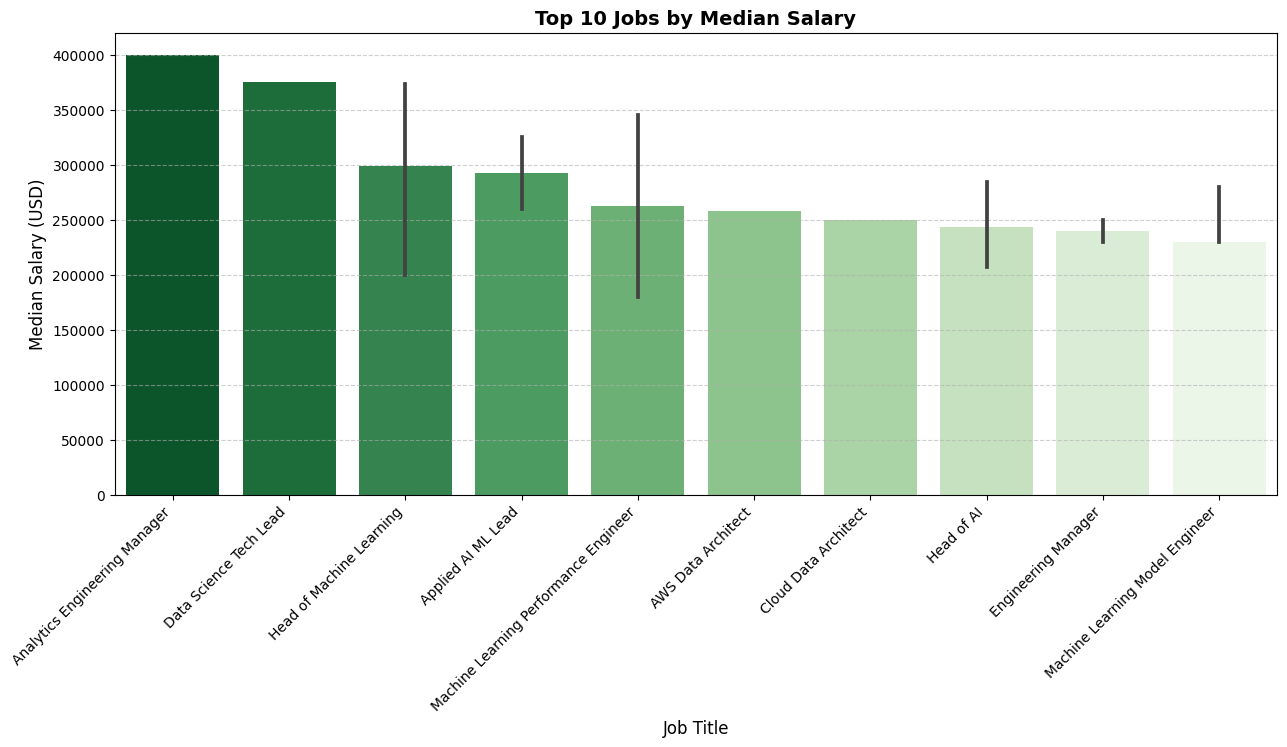

In [11]:
# Compute median salary per job title
job_salary = df.groupby("job_title")["salary_in_usd"].median().nlargest(10)  # Get top 10 highest paying jobs

plt.figure(figsize=(15, 6))
sns.barplot(
    data=df[df["job_title"].isin(job_salary.index)],  
    x="job_title", 
    y="salary_in_usd", 
    estimator=np.median, 
    order=job_salary.index,  # Ensure correct sorting
    palette="Greens_r" )
plt.title("Top 10 Jobs by Median Salary", fontsize=14, fontweight="bold")
plt.xlabel("Job Title", fontsize=12)
plt.ylabel("Median Salary (USD)", fontsize=12)
plt.xticks(rotation=45, ha="right")  # Align labels properly
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

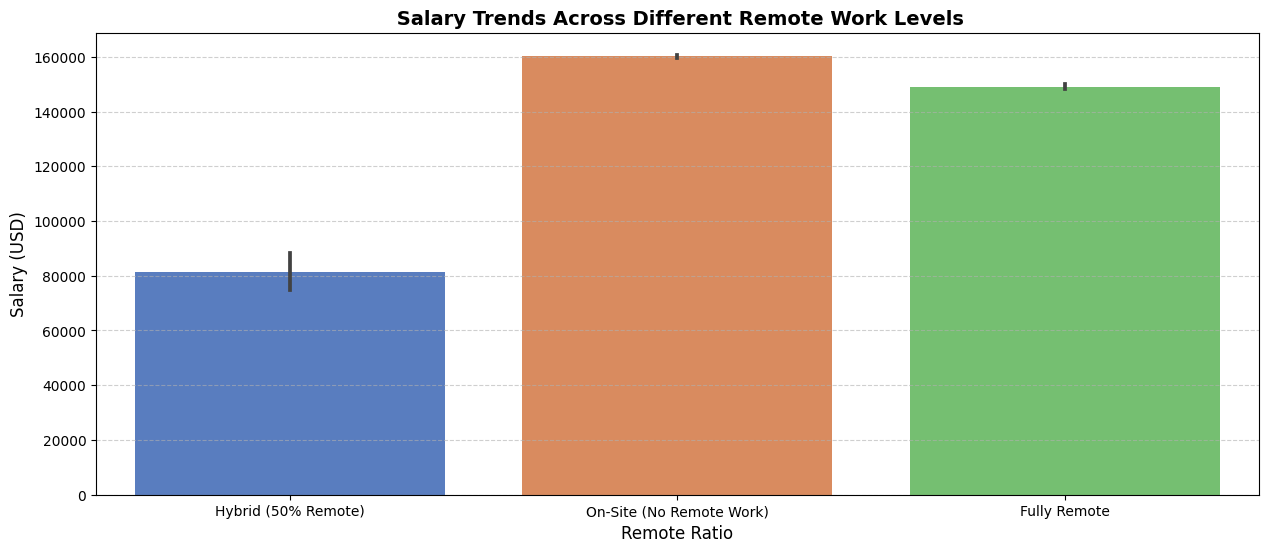

In [12]:
#Salary Trends Across Different Remote Work Levels
plt.figure(figsize=(15, 6))
sns.barplot(data=df, x='remote_ratio', y='salary_in_usd',estimator=np.mean,palette='muted')
plt.title(" Salary Trends Across Different Remote Work Levels", fontsize=14, fontweight="bold")
plt.xlabel("Remote Ratio", fontsize=12)
plt.ylabel("Salary (USD)", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

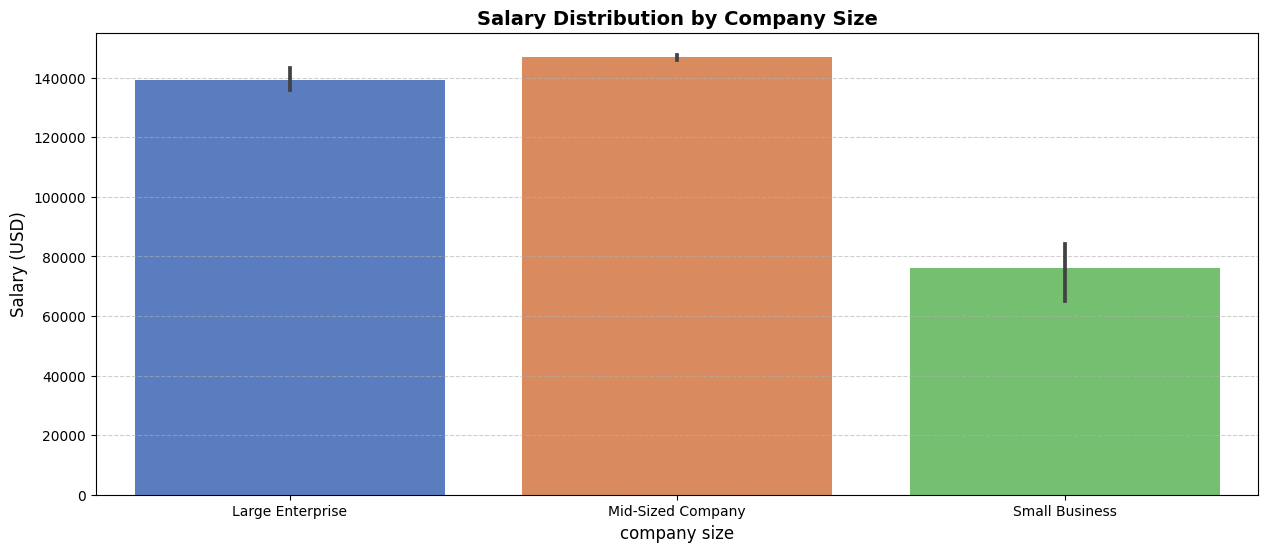

In [13]:
plt.figure(figsize=(15, 6))
sns.barplot(data=df, x='company_size', y='salary_in_usd',estimator=np.median,palette='muted')
plt.title("Salary Distribution by Company Size" ,fontsize=14, fontweight="bold")
plt.xlabel("company size",fontsize=12)
plt.ylabel("Salary (USD)",fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

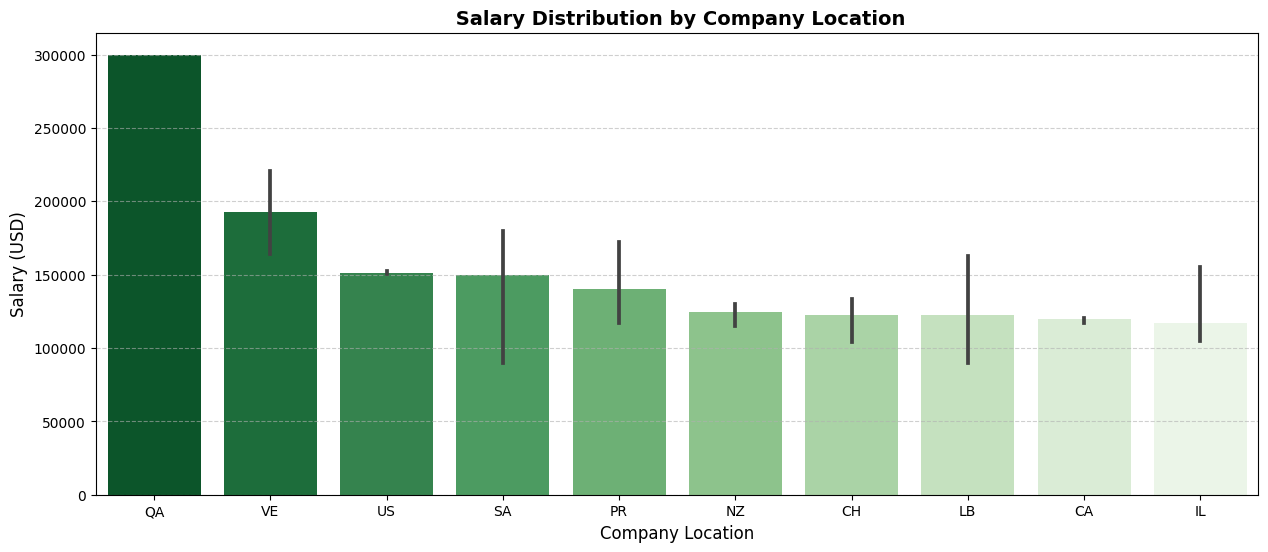

In [14]:
# Select Top 10 job titles to avoid clutter
top_company = df.groupby("company_location")["salary_in_usd"].median().nlargest(10)  # Get top 10 highest paying jobs
plt.figure(figsize=(15, 6))
sns.barplot( data=df[df["company_location"].isin(top_company.index)], x='company_location', y='salary_in_usd',estimator=np.median,palette='Greens_r',
order=top_company.index,  # Ensure correct sorting
)
plt.title(" Salary Distribution by Company Location",fontsize=14, fontweight="bold")
plt.xlabel("Company Location",fontsize=12)
plt.ylabel("Salary (USD)",fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

### Visualizing Employment Type, Remote Work, and Experience Level Distributions

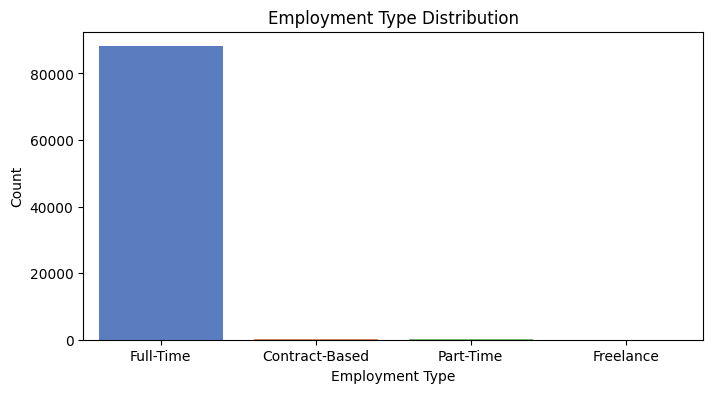

In [15]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df,x='employment_type',palette='muted',)
plt.title("Employment Type Distribution")
plt.xlabel("Employment Type")
plt.ylabel("Count")
plt.show()


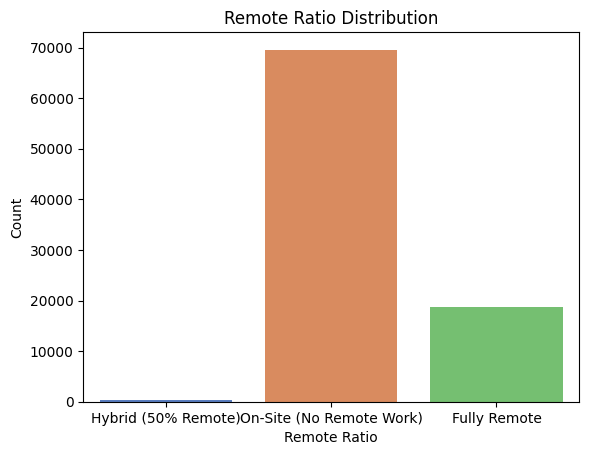

In [16]:
sns.countplot(x='remote_ratio', data=df, palette="muted",)
plt.title("Remote Ratio Distribution")
plt.xlabel("Remote Ratio")
plt.ylabel("Count")
plt.show()


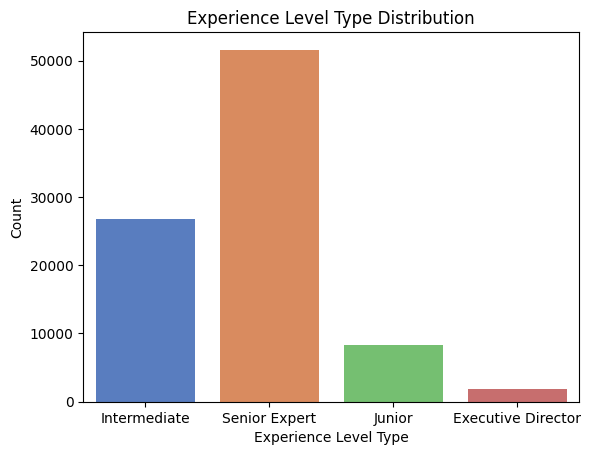

In [17]:
sns.countplot(x='experience_level', data=df, palette="muted",)
plt.title("Experience Level Type Distribution")
plt.xlabel("Experience Level Type")
plt.ylabel("Count")
plt.show()

## Data prepration for ML

### leble encoder

In [18]:
# Get all categorical (object) columns
categorical_columns = df.select_dtypes(include=['object']).columns


In [19]:
# Apply Label Encoding
for col in categorical_columns:
    le = LabelEncoder() 
    df[col] = le.fit_transform(df[col])


### Feature selection

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


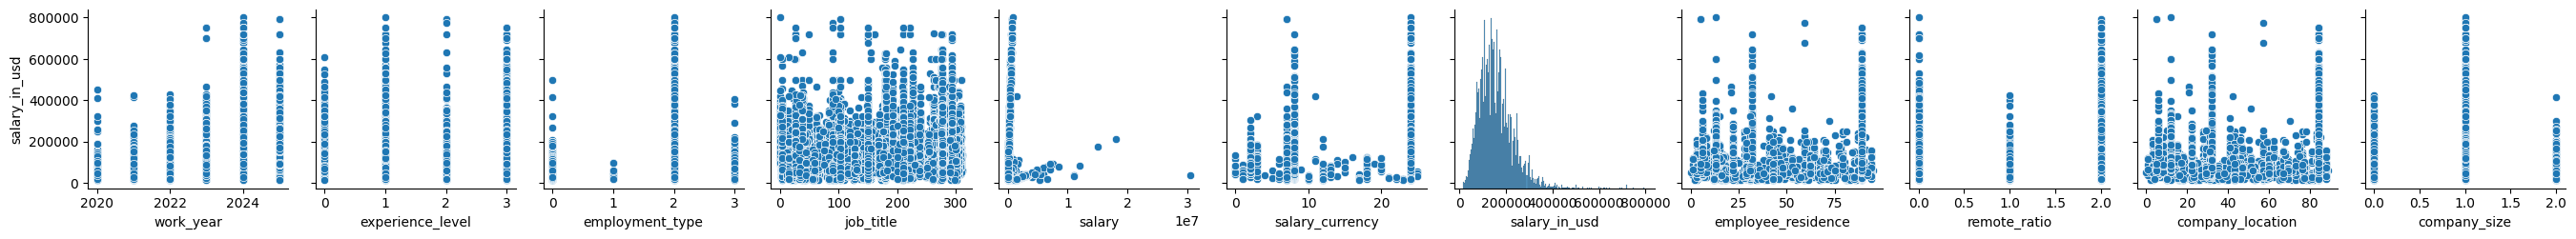

In [20]:
# Plot pairplot (Salary in usd vs. all numerical features)
sns.pairplot(df, y_vars=['salary_in_usd'], height=2.5)
plt.show()


Text(0.5, 1.0, 'Correlation Matrix Heatmap')

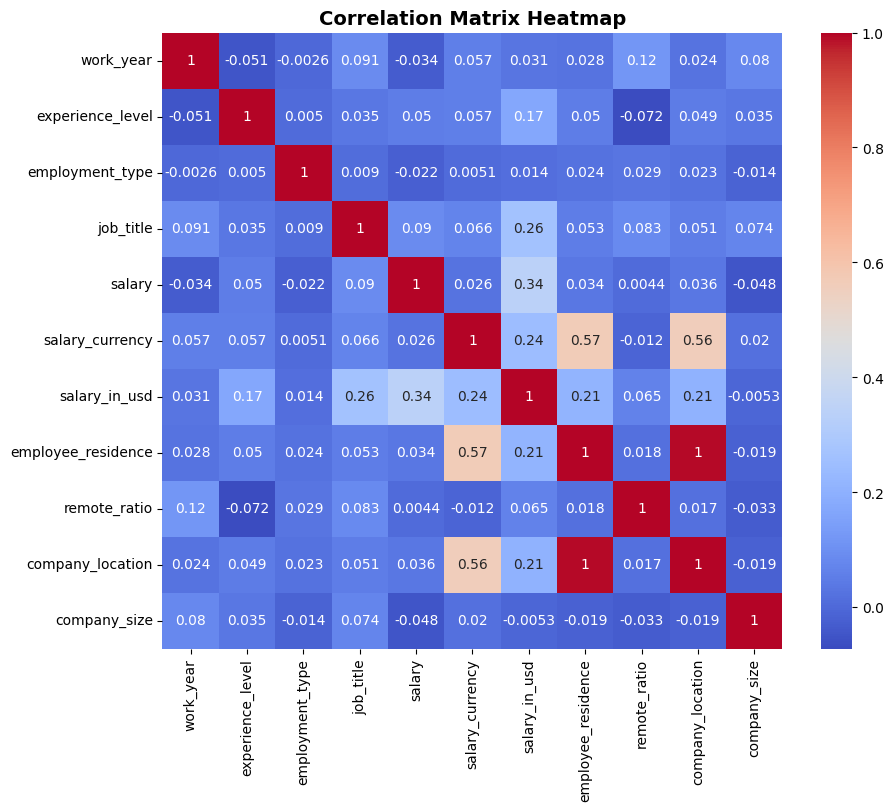

In [21]:
correlation_matrix=df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,cmap='coolwarm',annot=True)
plt.title("Correlation Matrix Heatmap", fontsize=14, fontweight='bold')


In [22]:
#slect feature and target
y=df['salary_in_usd']
X=df.drop(['salary_in_usd'],axis=1)

### Scaling

In [23]:
SC=StandardScaler()
X_scaler=SC.fit_transform(X)

### split data

In [24]:
X_train,X_test,y_train,y_test=train_test_split(X_scaler,y,test_size=0.2,shuffle=True,random_state=44)

## Model Training & Model Performance

### LinearRegression

In [25]:
LR=LinearRegression()
LR.fit(X_train,y_train)
#data pred
y_pred_Test_LR=LR.predict(X_test)
y_pred_Train_LR=LR.predict(X_train)
#score
score_train_LR=LR.score(X_train, y_train)
score_test_LR=LR.score(X_test, y_test)
#cross validation
CV_LR=cross_val_score(LR,X,y,scoring='neg_mean_squared_error',cv=5)
CV_LR_mean=np.mean(CV_LR)
#Mean squared error 
MSR_Test_LR=mean_squared_error(y_test,y_pred_Test_LR)
MSR_Train_LR=mean_squared_error(y_train,y_pred_Train_LR)
#print metraces
print('Metraces for Linear Regression')
print('Train Score is:',score_train_LR)
print('Test Score is:',score_test_LR)
print('Mean Squared Error Train is:',MSR_Train_LR)
print('Mean Squared Error Test is:',MSR_Test_LR)
print('Cross Validation is:',CV_LR)
print('Mean Cross Validation is:',CV_LR_mean)

Metraces for Linear Regression
Train Score is: 0.2460949892829214
Test Score is: 0.24813439831174022
Mean Squared Error Train is: 4080671077.4343276
Mean Squared Error Test is: 4047410867.115819
Cross Validation is: [-4.73776321e+09 -3.61872681e+09 -3.89522653e+09 -3.91792596e+09
 -8.09766953e+09]
Mean Cross Validation is: -4853462407.358978


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


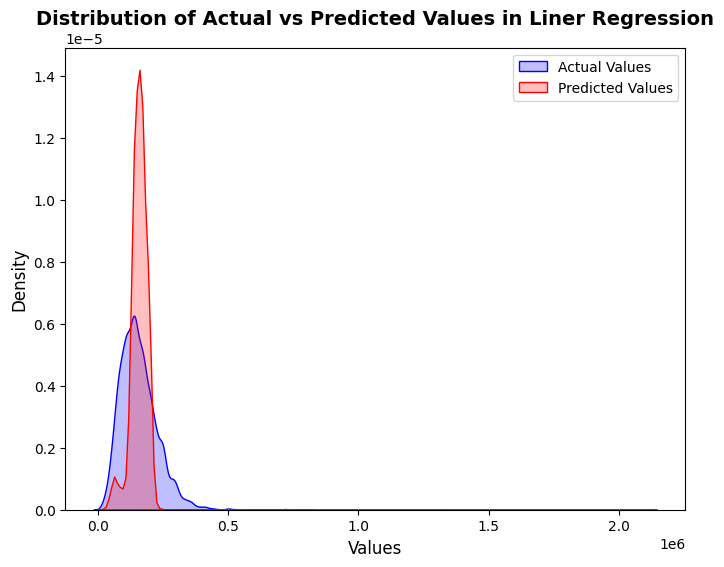

In [26]:
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_LR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in Liner Regression', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### Ridge

In [27]:
R=Ridge()
R.fit(X_train,y_train)
#data pred
y_pred_Test_R=R.predict(X_test)
y_pred_Train_R=R.predict(X_train)
#Score
score_train_R=R.score(X_train, y_train)
score_test_R=R.score(X_test, y_test)
#cross validation
CV_R=cross_val_score(R,X,y,scoring='neg_mean_squared_error',cv=5)
CV_R_mean=np.mean(CV_R)
#Mean squared error 
MSR_Test_R=mean_squared_error(y_test,y_pred_Test_R)
MSR_Train_R=mean_squared_error(y_train,y_pred_Train_R)
#print metraces
print('Metraces for Ridge')
print('Train Score is:',score_train_R)
print('Test Score is:',score_test_R)
print('Mean Squared Error Train is:',MSR_Train_R)
print('Mean Squared Error Test is:',MSR_Test_R)
print('Cross Validation is:',CV_R)
print('Mean Cross Validation is:',CV_R_mean)


Metraces for Ridge
Train Score is: 0.24609498776722172
Test Score is: 0.248134782765283
Mean Squared Error Train is: 4080671085.6383743
Mean Squared Error Test is: 4047408797.541891
Cross Validation is: [-4.73775991e+09 -3.61872792e+09 -3.89522304e+09 -3.91792593e+09
 -8.09763767e+09]
Mean Cross Validation is: -4853454897.115431


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


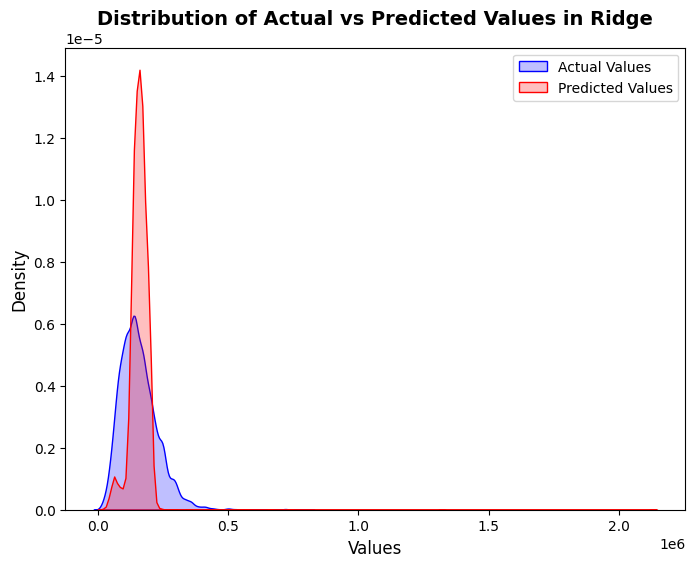

In [28]:
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_R, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in Ridge', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### RandomForestRegressor

In [29]:
RFR=RandomForestRegressor()
RFR.fit(X_train,y_train)
#data pred
y_pred_Test_RFR=RFR.predict(X_test)
y_pred_Train_RFR=RFR.predict(X_train)
#Score
score_train_RFR=RFR.score(X_train, y_train)
score_test_RFR=RFR.score(X_test, y_test)
#cross validation
CV_RFR=cross_val_score(RFR,X,y,scoring='neg_mean_squared_error',cv=5)
CV_RFR_mean=np.mean(CV_RFR)
#Mean squared error 
MSR_Test_RFR=mean_squared_error(y_test,y_pred_Test_RFR)
MSR_Train_RFR=mean_squared_error(y_train,y_pred_Train_RFR)
#print metraces
print('Metraces for RandomForestRegressor')
print('Train Score is:',score_train_RFR)
print('Test Score is:',score_test_RFR)
print('Mean Squared Error Train is:',MSR_Train_RFR)
print('Mean Squared Error Test is:',MSR_Test_RFR)
print('Cross Validation is:',CV_RFR)
print('Mean Cross Validation is:',CV_RFR_mean)

Metraces for RandomForestRegressor
Train Score is: 0.9988737956933871
Test Score is: 0.9909041672832777
Mean Squared Error Train is: 6095820.131114693
Mean Squared Error Test is: 48964299.0721548
Cross Validation is: [-1.30824503e+08 -5.56990199e+07 -3.78385060e+07 -3.33201036e+06
 -1.21832919e+08]
Mean Cross Validation is: -69905391.76047964


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


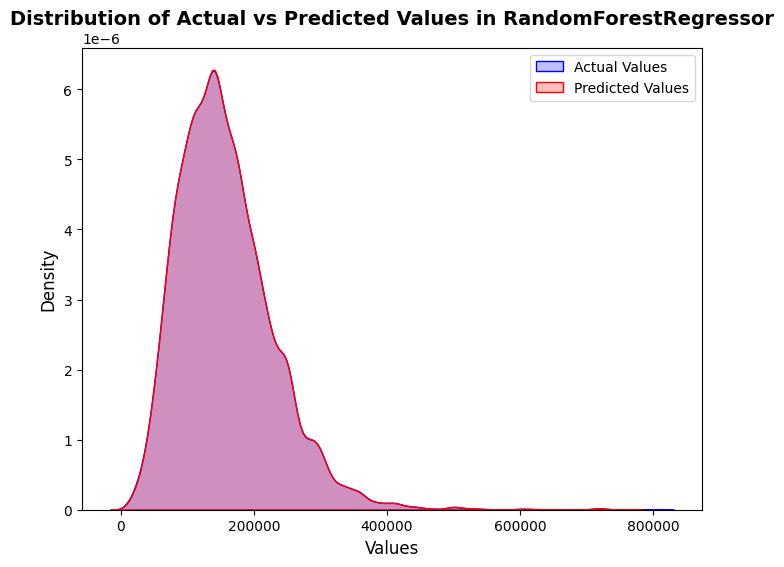

In [30]:
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_RFR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in RandomForestRegressor', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### DecisionTreeRegressor

In [31]:
DTR=DecisionTreeRegressor()
DTR.fit(X_train,y_train)
#data pred
y_pred_Test_DTR=DTR.predict(X_test)
y_pred_Train_DTR=DTR.predict(X_train)
#score
score_train_DTR=DTR.score(X_train, y_train)
score_test_DTR=DTR.score(X_test, y_test)
#cross validation
CV_DTR=cross_val_score(DTR,X,y,scoring='neg_mean_squared_error',cv=5)
CV_DTR_mean=np.mean(CV_DTR)
#Mean squared error 
MSR_Test_DTR=mean_squared_error(y_test,y_pred_Test_DTR)
MSR_Train_DTR=mean_squared_error(y_train,y_pred_Train_DTR)
#print metraces
print('Metraces for DecisionTreeRegressor')
print('Train Score is:',score_train_DTR)
print('Test Score is:',score_test_DTR)
print('Mean Squared Error Train is:',MSR_Train_DTR)
print('Mean Squared Error Test is:',MSR_Test_DTR)
print('Cross Validation is:',CV_DTR)
print('Mean Cross Validation is:',CV_DTR_mean)

Metraces for DecisionTreeRegressor
Train Score is: 1.0
Test Score is: 0.9865039789767125
Mean Squared Error Train is: 0.0
Mean Squared Error Test is: 72651205.25506575
Cross Validation is: [-1.98233109e+08 -1.22191071e+08 -2.84134545e+07 -4.67958919e+06
 -1.85879188e+08]
Mean Cross Validation is: -107879282.40041351


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


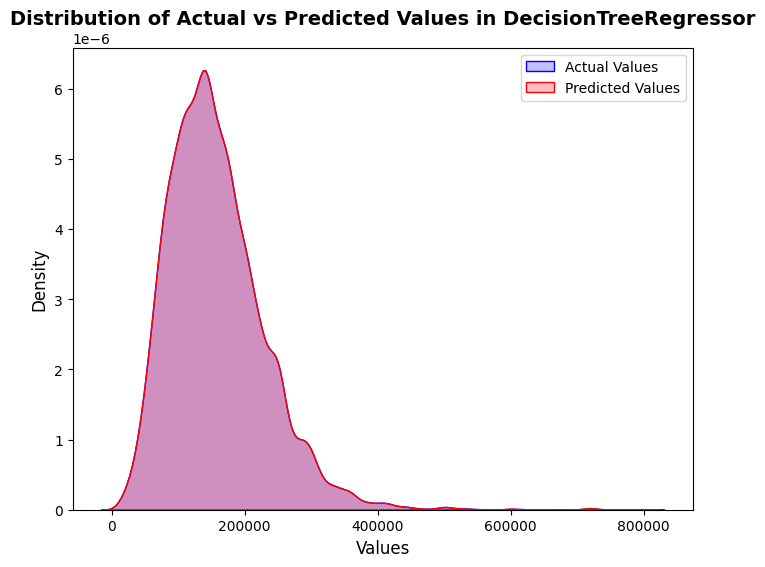

In [32]:
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_DTR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values',fontsize=12)
plt.ylabel('Density',fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in DecisionTreeRegressor',fontsize=14, fontweight='bold')
plt.legend()
plt.show()

### GradientBoostingRegresso 

In [33]:

GBR = GradientBoostingRegressor()
GBR.fit(X_train, y_train)

y_pred_Test_GBR = GBR.predict(X_test)
y_pred_Train_GBR = GBR.predict(X_train)

# Score evaluation
score_train_GBR = GBR.score(X_train, y_train)
score_test_GBR = GBR.score(X_test, y_test)

# Cross-validation
CV_GBR = cross_val_score(GBR, X, y, scoring='neg_mean_squared_error', cv=5)
CV_GBR_mean = np.mean(CV_GBR)

# Mean Squared Error
MSR_Test_GBR = mean_squared_error(y_test, y_pred_Test_GBR)
MSR_Train_GBR = mean_squared_error(y_train, y_pred_Train_GBR)

# Print metrics
print('Metrics for GradientBoostingRegressor')
print('Train Score is:', score_train_GBR)
print('Test Score is:', score_test_GBR)
print('Mean Squared Error Train is:', MSR_Train_GBR)
print('Mean Squared Error Test is:', MSR_Test_GBR)
print('Cross Validation is:', CV_GBR)
print('Mean Cross Validation is:', CV_GBR_mean)


Metrics for GradientBoostingRegressor
Train Score is: 0.9977220155714949
Test Score is: 0.9940090045404676
Mean Squared Error Train is: 12330074.797360584
Mean Squared Error Test is: 32250471.458337583
Cross Validation is: [-63770389.093428   -20317662.23492521 -20710538.25472958
 -14015514.07843678 -79765655.65931433]
Mean Cross Validation is: -39715951.86416678


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


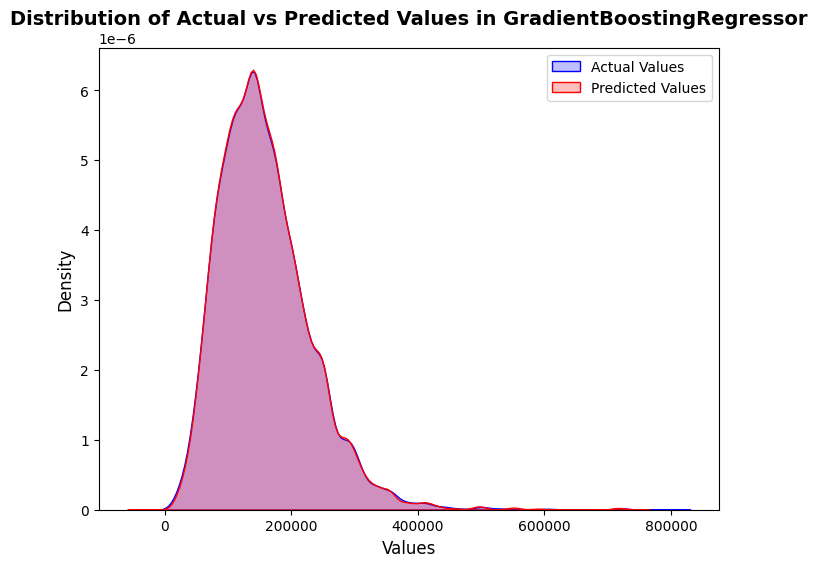

In [34]:
# Visualization
plt.figure(figsize=(8, 6))
sns.kdeplot(y_test, label='Actual Values', color='blue', fill=True)
sns.kdeplot(y_pred_Test_GBR, label='Predicted Values', color='red', fill=True)
plt.xlabel('Values', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title('Distribution of Actual vs Predicted Values in GradientBoostingRegressor', fontsize=14, fontweight='bold')
plt.legend()
plt.show()

## Performance Comparison of Regression Models

In [35]:
# Define metrics for each model
models = ["Linear Regression", "Ridge Regression", "Random Forest Regressor", "Decision Tree Regressor","GradientBoostingRegressor"]

train_scores = [score_train_LR, score_train_R, score_train_RFR, score_train_DTR,score_train_GBR]
test_scores = [score_test_LR, score_test_R, score_test_RFR, score_test_DTR,score_test_GBR]
cv_scores = [CV_LR_mean, CV_R_mean, CV_RFR_mean, CV_DTR_mean,CV_GBR_mean]
mse_train = [MSR_Train_LR, MSR_Train_R, MSR_Train_RFR, MSR_Train_DTR,MSR_Train_GBR]
mse_test = [MSR_Test_LR, MSR_Test_R, MSR_Test_RFR, MSR_Test_DTR,MSR_Test_GBR]

# Create a DataFrame to store the results
df_comparison = pd.DataFrame({
    "Model": models,
    "Train Score": train_scores,
    "Test Score": test_scores,
    "Mean CV Score": cv_scores,
    "MSE Train": mse_train,
    "MSE Test": mse_test
})

# Sort models by Test Score (Descending Order)
df_comparison = df_comparison.sort_values(by="Test Score", ascending=False)

# Print the table
print("Model Performance Comparison:\n")
print(df_comparison.to_string())


Model Performance Comparison:

                       Model  Train Score  Test Score  Mean CV Score     MSE Train      MSE Test
4  GradientBoostingRegressor     0.997722    0.994009  -3.971595e+07  1.233007e+07  3.225047e+07
2    Random Forest Regressor     0.998874    0.990904  -6.990539e+07  6.095820e+06  4.896430e+07
3    Decision Tree Regressor     1.000000    0.986504  -1.078793e+08  0.000000e+00  7.265121e+07
1           Ridge Regression     0.246095    0.248135  -4.853455e+09  4.080671e+09  4.047409e+09
0          Linear Regression     0.246095    0.248134  -4.853462e+09  4.080671e+09  4.047411e+09


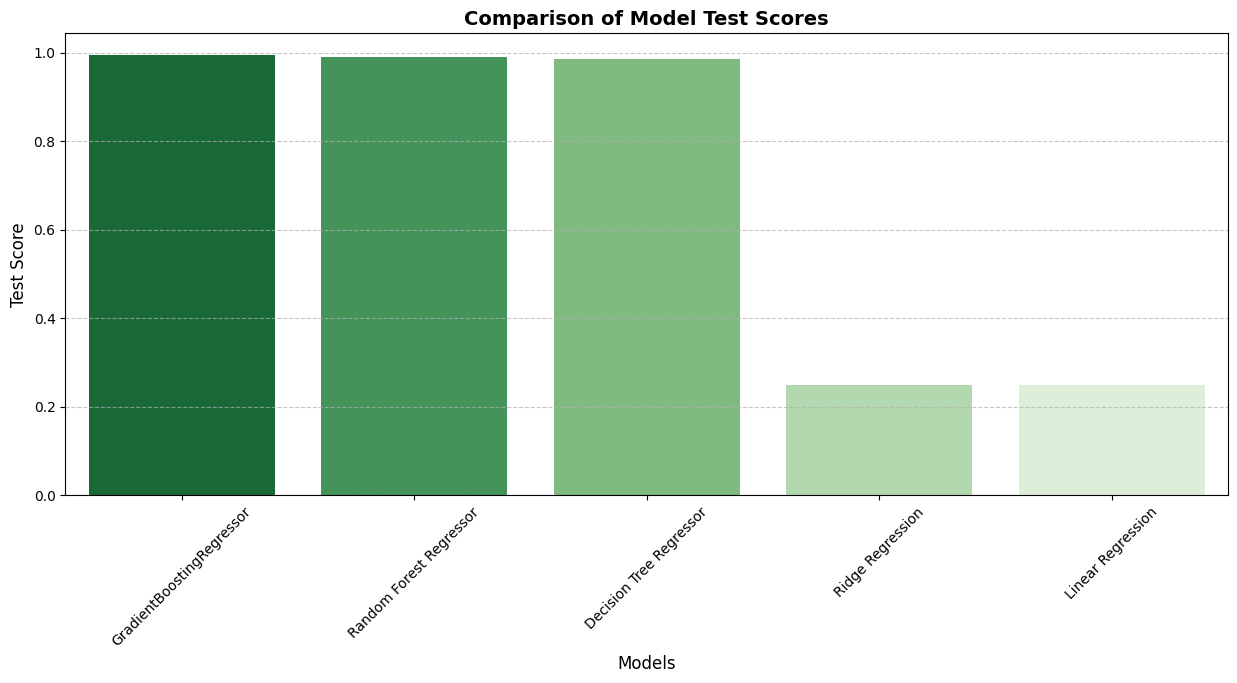

In [36]:
# Set plot style
plt.figure(figsize=(15, 6))
sns.barplot(x=df_comparison["Model"], y=df_comparison["Test Score"], palette="Greens_r")

# Formatting the plot
plt.xlabel("Models", fontsize=12)
plt.ylabel("Test Score", fontsize=12)
plt.title("Comparison of Model Test Scores", fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
# Show the plot
plt.show()

## 🚀 Loved this notebook?
If you found it helpful or insightful, please show some love with an upvote! 👍 Your support fuels more content like this.

💬 Got feedback or ideas? Drop a comment below—I’d love to hear your thoughts!

Happy learning, and keep exploring! 🌟